# Disclaimer: 
En la actividad AI1 elegi el dataset de "Principales aerolíneas de cabotaje por mes", sin embargo, 
para este ejercicio, me resulto mas interesante resolver el dataset de **"Airfoil Self-Noise"**

# Ensayos del dataset
Este dataset surge de un analisis de tipos de cuerdas para un perfil aerodinamico NACA (0012), donde se realiza un ensayo por cuerda, velocidad y angulo de ataque. 
Este perfil es un perfil simetrico (no genera sustentacion en angulo de ataque de 0°)

En cada ensayo, se obtiene la diferencia de presion (medida y atmosferica) en funcion del tiempo p´(t), de la cual se le hace la transformada rapida de fourier FFT para obtener 
la presion sonora [dB] en funcion de cada banda de frecuencia (analisis espectral de potencia). Esto se realiza ya que en cada ensayo varia la capa limite turbulenta 
pasando por el borde de fuga del perfil, y justo eso se quiere medir, el sonido que realizan los remolinos turbulentos de la capa limite.

A su vez, cada fila es una banda de ensayo, por lo que hay 1503 filas pero solo 106 ensayos. 

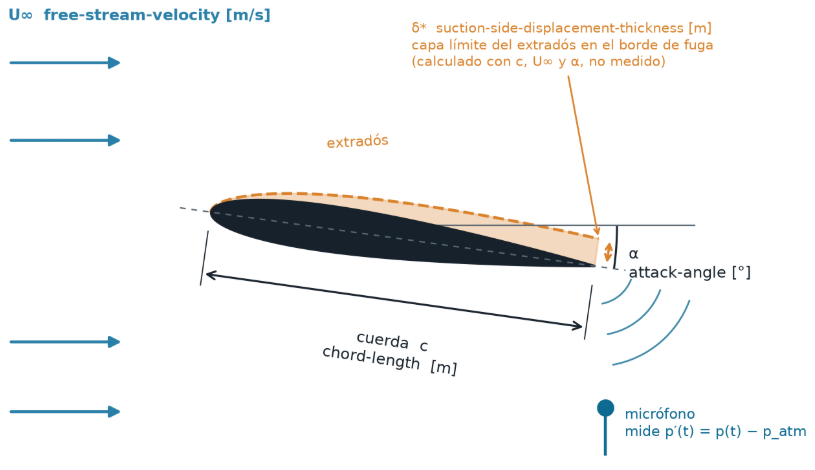

# Tipos de variables

Las variables que tenemos son las siguientes:

1. Frecuencia [Hz]: variable cuantitativa discreta
2. Angulo de ataque [°]: variable categorica ordinal
3. Cuerda [m]: variable categorica ordinal
4. Velocidad [m/s]: variable categorica ordinal
5. Espesor de desplazamiento [m]: variable cuantitativa continua
6. SPL [db]: variable cuantitativa continua

# Cargo los datos:

In [1]:
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt, numpy as np
%matplotlib inline
cols = ["f", "alpha", "c", "U", "delta", "SPL"]
df = pd.read_csv("airfoil+self+noise/airfoil_self_noise.dat", sep=r"\s+", header=None, names=cols)

# Estadistica descriptiva

In [2]:
summary = df.describe().T
summary["asimetria"] = df.skew()            
summary["valores unicos"] = df.nunique()     
summary["faltantes"] = df.isna().sum()
summary.round(3)

,count,mean,std,min,25%,50%,75%,max,asimetria,valores unicos,faltantes
f,1503.0,2886.381,3152.573,200.000,800.000,1600.000,4000.000,20000.000,2.137,21,0
alpha,1503.0,6.782,5.918,0.000,2.000,5.400,9.900,22.200,0.689,27,0
c,1503.0,0.137,0.094,0.025,0.051,0.102,0.229,0.305,0.457,6,0
U,1503.0,50.861,15.573,31.700,39.600,39.600,71.300,71.300,0.236,4,0
delta,1503.0,0.011,0.013,0.000,0.003,0.005,0.016,0.058,1.702,105,0
SPL,1503.0,124.836,6.899,103.380,120.191,125.721,129.996,140.987,-0.419,1456,0


## Resultados

1. Podemos observar que no hay datos faltantes en ninguna columna.

2. Tambien, que solo se realizaron ensayos para 6 cuerdas y 4 velocidades distintas (como habiamos mencionado anteriormente), por lo que las tomamos como variables categoricas ordinales.

3. Otro dato interesante, es que la mediana de U y el percentil 25 dan exactamente igual, por lo que no hay valores entre medio de ambos, y la que mas se ensayo fue la de 39.6 m/s.

4. Por ultimo, encontramos un asimetria muy alta en la frecuencia, es decir que tendremos una cola larga a la derecha.

# Relacion entre variables

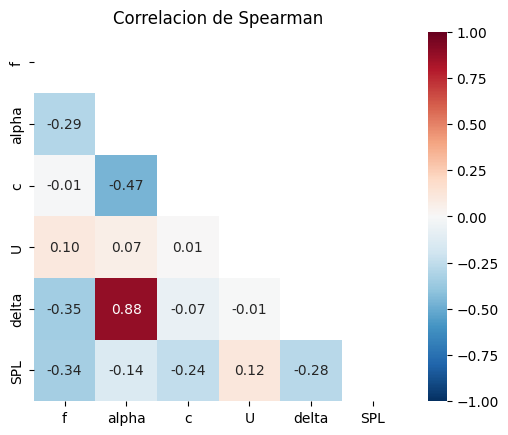

In [3]:
corr = df.corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))  
ax = sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
ax.set_title("Correlacion de Spearman")
plt.show()

## Resultados

1. Podemos observar que la relacion mas fuerte es delta con alpha, y esto tiene un sentido fisico: el delta de desplazamiento se calcula en funcion del angulo de ataque del perfil debido a la capa limite. 

2. La otra variable que tiene relacion moderada es la cuerda con el angulo de ataque, debido a que las cuerdas grandes solo se probaron a angulos chicos.

3. El resto de variables solo presentan relaciones debiles con el SPL, resultando en un hallazgo para el analisis.

# Grafico de SPL en funcion de la cuerda:

El primer grafico va a mostrar como varia el ruido en funcion de la cuerda, manteniendo alpha = 0°, y variando la velocidad (una por color). Se graficara un boxplot de la distribucion de SPL para cada cuerda y velocidad.

Se espera que a mayor cuerda, el ruido obtenido sea menor debido a que aumenta el espesor geometrico del perfil .

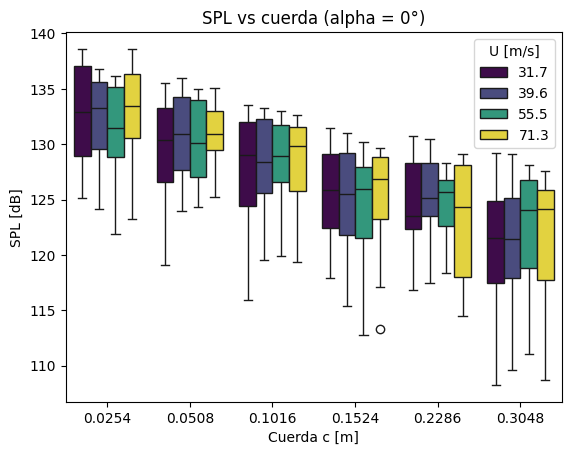

In [4]:
a0 = df[df["alpha"] == 0]  
ax = sns.boxplot(data=a0, x="c", y="SPL", hue="U", palette="viridis")
ax.set(xlabel="Cuerda c [m]", ylabel="SPL [dB]", title="SPL vs cuerda (alpha = 0°)")
ax.legend(title="U [m/s]")
plt.show()

## Resultados

Como se menciono anteriormente, el SPL va disminuyendo a lo largo de la cuerda a nivel general, pero para cada cuerda hay resultados distintos para una velocidad determinada. Por ejemplo, analizando las medianas de SPL, en la primer cuerda, la mayor presion sonora se obtiene para v=71.3, sin embargo para la quinta cuerda, para v=55.5. Esto refuerza la debil relacion entre el SPL y la velocidad que vimos anteriormente, donde el efecto de U es chico al lado de la dispersion.

Otro dato interesante se ve en los bigotes de la ultima cuerda (la mayor), donde hay una distribucion mucho mas amplia de valores. 

# Grafico de SPL vs alpha

En este caso, seleccionamos la cuerda de 0.0254m, y analizamos como varia la presion sonora en funcion del angulo de ataque para cada velocidad. Aca se espera que, a mayor angulo de ataque, la presion sonora disminuye debido al desprendimiento de la capa limite antes del borde de fuga.

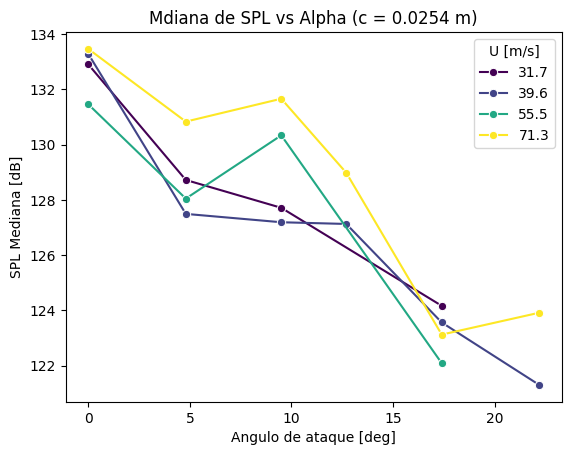

In [5]:
c0 = df[df["c"] == 0.0254]
ax = sns.lineplot(data=c0, x="alpha", y="SPL", hue="U", estimator="median",
                  errorbar=None, marker="o", palette="viridis")
ax.set(xlabel="Angulo de ataque [deg]", ylabel="SPL Mediana [dB]",
       title="Mdiana de SPL vs Alpha (c = 0.0254 m)")
ax.legend(title="U [m/s]")
plt.show()

## Resultados:

Como mencionamos anteriormente, la presion sonora disminye en funcion del angulo de ataque. Una hipotesis es que, mientras el angulo de ataque va aumentando, la capa limite no se puede mantener pegada a lo largo del perfil, desprendiendose en % de la cuerda menor, y generando turbulencias con menor frecuencia (remolinos mas grandes). Estos quiere decir que se verian en una banda de frecuencia menor, por lo que el proximo grafico estudiara esto mismo.

Mientras que con respecto a la velocidad, a mayor velocidad, la capa limite se mantiene pegada mas tiempo. Una hipotesis es que aumenta el numero de Reynolds del perfil y hace aun mas turbulento el flujo, generando aun mayor ruido.

# Grafico de espectro de SPL por alpha

Tal como mencionamos antes, se estudia que le pasa a la cuerda anterior a la velocidad de 71.3 m/s en funcion de alpha y del espectro de frecuencias que se ensayo. 

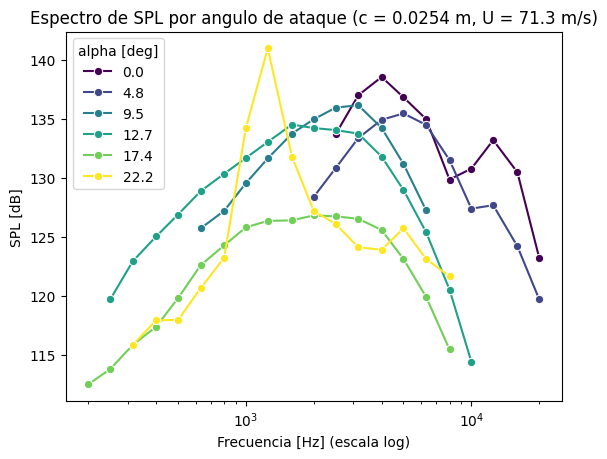

In [6]:
run = df[(df["c"] == 0.0254) & (df["U"] == 71.3)]   
ax = sns.lineplot(data=run, x="f", y="SPL", hue="alpha", marker="o", palette="viridis")
ax.set_xscale("log")   
ax.set(xlabel="Frecuencia [Hz] (escala log)", ylabel="SPL [dB]",
       title="Espectro de SPL por angulo de ataque (c = 0.0254 m, U = 71.3 m/s)")
ax.legend(title="alpha [deg]")
plt.show()

## Resultados:

Ahora si podemos explicar lo que vimos en el segundo grafico. A menor angulo de ataque, el pico de sonido esta en frecuencias mas altas, donde los remolinos son mas chicos y mas agudos. A angulos de ataques mas altos, los remolinos son mas grandes, consistente con que se desprenden antes del borde de fuga, siendo estos mas grandes y mas graves. Para el caso de 22.2°, encontramos un pico muy grande a cierta frecuencia. Una hipotesis de esto es que justo en ese angulo el perfil entra en perdida de sustentacion, comportandose como una especie de "pared" frente al flujo incidente.
